In [1]:
import pandas as pd

# Load the dataset (semicolon-separated, as we saw in Excel)
df = pd.read_csv('data/TrainRidesCleaned.csv', sep=';')

# Quick look
print(df.shape)
df.head()

(31653, 18)


,Transaction ID,Date of Purchase,Time of Purchase,Purchase Type,Payment Method,Railcard,Ticket Class,Ticket Type,Price,Departure Station,Arrival Destination,Date of Journey,Departure Time,Arrival Time,Actual Arrival Time,Journey Status,Reason for Delay,Refund Request
0,da8a6ba8-b3dc-4677-b176,08/12/2023,12:41:11,Online,Contactless,Adult,Standard,Advance,43,London Paddington,Liverpool Lime Street,01/01/2024,11:00:00,13:30:00,13:30:00,On Time,NaN,No
1,b0cdd1b0-f214-4197-be53,16/12/2023,11:23:01,Station,Credit Card,Adult,Standard,Advance,23,London Kings Cross,York,01/01/2024,09:45:00,11:35:00,11:40:00,Delayed,Signal Failure,No
2,f3ba7a96-f713-40d9-9629,19/12/2023,19:51:27,Online,Credit Card,NaN,Standard,Advance,3,Liverpool Lime Street,Manchester Piccadilly,02/01/2024,18:15:00,18:45:00,18:45:00,On Time,NaN,No
3,b2471f11-4fe7-4c87-8ab4,20/12/2023,23:00:36,Station,Credit Card,NaN,Standard,Advance,13,London Paddington,Reading,01/01/2024,21:30:00,22:30:00,22:30:00,On Time,NaN,No
4,2be00b45-0762-485e-a7a3,27/12/2023,18:22:56,Online,Contactless,NaN,Standard,Advance,76,Liverpool Lime Street,London Euston,01/01/2024,16:45:00,19:00:00,19:00:00,On Time,NaN,No


In [2]:
# Check for missing values and data types
df.info()
print("\nMissing values:\n", df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31653 entries, 0 to 31652
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Transaction ID       31653 non-null  object
 1   Date of Purchase     31653 non-null  object
 2   Time of Purchase     31653 non-null  object
 3   Purchase Type        31653 non-null  object
 4   Payment Method       31653 non-null  object
 5   Railcard             10735 non-null  object
 6   Ticket Class         31653 non-null  object
 7   Ticket Type          31653 non-null  object
 8   Price                31653 non-null  int64 
 9   Departure Station    31653 non-null  object
 10  Arrival Destination  31653 non-null  object
 11  Date of Journey      31653 non-null  object
 12  Departure Time       31653 non-null  object
 13  Arrival Time         31653 non-null  object
 14  Actual Arrival Time  29773 non-null  object
 15  Journey Status       31653 non-null  object
 16  Reas

In [3]:
# Fill missing Railcard with 'None' (since NaN here means no railcard)
df['Railcard'] = df['Railcard'].fillna('None')

# Create target variable: 1 if Delayed, 0 otherwise (excluding Cancelled for now)
df_model = df[df['Journey Status'].isin(['On Time', 'Delayed'])].copy()
df_model['is_delayed'] = (df_model['Journey Status'] == 'Delayed').astype(int)

print(df_model['is_delayed'].value_counts())

is_delayed
0    27481
1     2292
Name: count, dtype: int64


In [4]:
# Select simple, meaningful features for prediction
features = ['Ticket Class', 'Railcard', 'Departure Station', 'Payment Method', 'Price']
X = df_model[features]
y = df_model['is_delayed']

# Convert categorical columns to numbers (one-hot encoding)
X_encoded = pd.get_dummies(X, columns=['Ticket Class', 'Railcard', 'Departure Station', 'Payment Method'], drop_first=True)

print(X_encoded.shape)
X_encoded.head()

(29773, 18)


,Price,Ticket Class_Standard,Railcard_Disabled,Railcard_None,Railcard_Senior,Departure Station_Bristol Temple Meads,Departure Station_Edinburgh Waverley,Departure Station_Liverpool Lime Street,Departure Station_London Euston,Departure Station_London Kings Cross,Departure Station_London Paddington,Departure Station_London St Pancras,Departure Station_Manchester Piccadilly,Departure Station_Oxford,Departure Station_Reading,Departure Station_York,Payment Method_Credit Card,Payment Method_Debit Card
0,43,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False
1,23,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False
2,3,True,False,True,False,False,False,True,False,False,False,False,False,False,False,False,True,False
3,13,True,False,True,False,False,False,False,False,False,True,False,False,False,False,False,True,False
4,76,True,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,False


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Split data: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# Train a simple logistic regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Predict on test data
y_pred = model.predict(X_test)

# Check accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9378673383711167

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.99      0.97      5488
           1       0.70      0.36      0.48       467

    accuracy                           0.94      5955
   macro avg       0.82      0.68      0.72      5955
weighted avg       0.93      0.94      0.93      5955



In [6]:
# Retrain with class_weight='balanced' to handle the imbalance
model_balanced = LogisticRegression(max_iter=1000, class_weight='balanced')
model_balanced.fit(X_train, y_train)

y_pred_balanced = model_balanced.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_balanced))
print("\nClassification Report:\n", classification_report(y_test, y_pred_balanced))

Accuracy: 0.8137699412258607

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.82      0.89      5488
           1       0.26      0.73      0.38       467

    accuracy                           0.81      5955
   macro avg       0.62      0.78      0.64      5955
weighted avg       0.92      0.81      0.85      5955



In [7]:
import numpy as np

# Get feature importance from the balanced model's coefficients
feature_importance = pd.DataFrame({
    'feature': X_encoded.columns,
    'coefficient': model_balanced.coef_[0]
})

# Sort by absolute value of coefficient (importance regardless of direction)
feature_importance['abs_coefficient'] = feature_importance['coefficient'].abs()
feature_importance = feature_importance.sort_values('abs_coefficient', ascending=False)

print(feature_importance.head(10))

                                    feature  coefficient  abs_coefficient
11      Departure Station_London St Pancras    -5.083602         5.083602
14                Departure Station_Reading    -3.113596         3.113596
17                Payment Method_Debit Card     3.032217         3.032217
6      Departure Station_Edinburgh Waverley     2.734280         2.734280
4                           Railcard_Senior    -2.613592         2.613592
13                 Departure Station_Oxford     2.197642         2.197642
12  Departure Station_Manchester Piccadilly     1.827489         1.827489
15                   Departure Station_York     1.165918         1.165918
2                         Railcard_Disabled    -1.133941         1.133941
7   Departure Station_Liverpool Lime Street     1.100291         1.100291


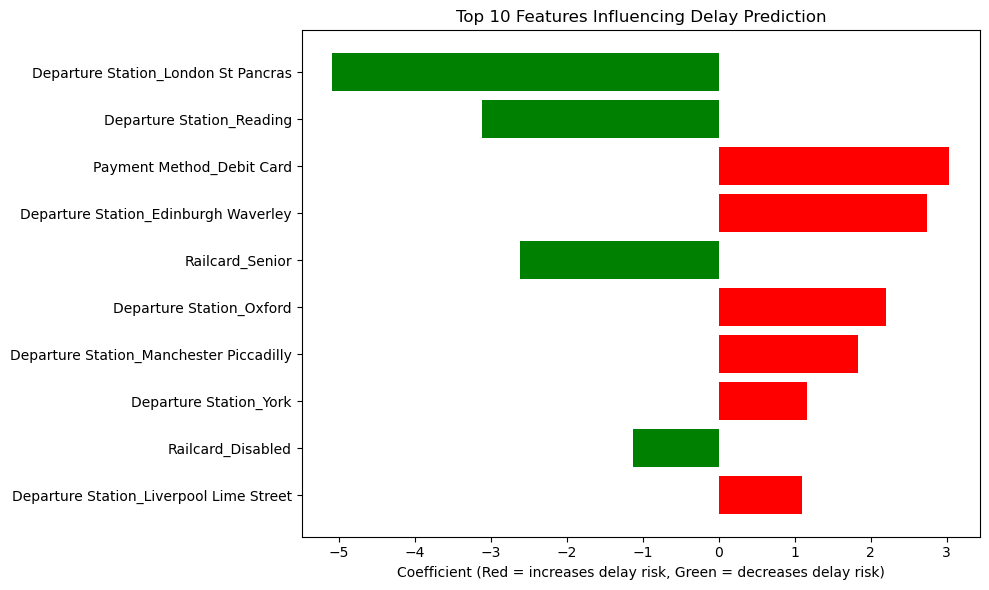

In [8]:
import matplotlib.pyplot as plt

# Plot top 10 features by importance
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))
colors = ['red' if x > 0 else 'green' for x in top_features['coefficient']]
plt.barh(top_features['feature'], top_features['coefficient'], color=colors)
plt.xlabel('Coefficient (Red = increases delay risk, Green = decreases delay risk)')
plt.title('Top 10 Features Influencing Delay Prediction')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

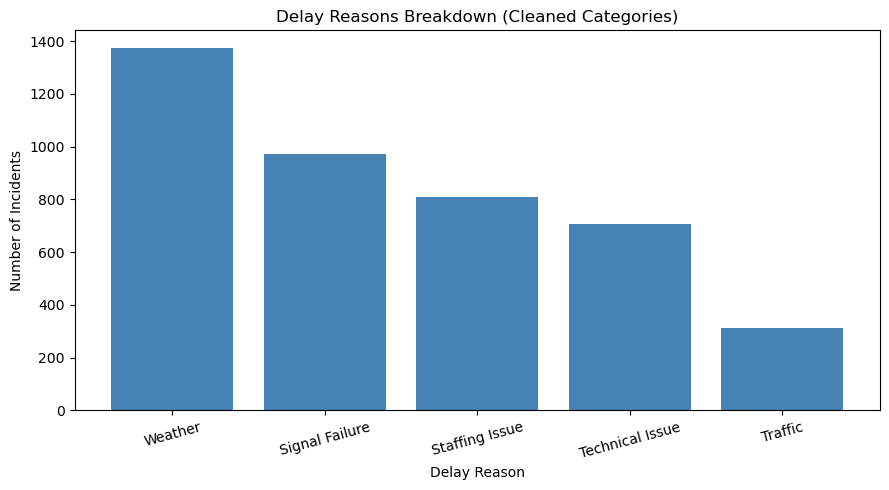

In [9]:
# Delay reasons data (from our Athena query)
delay_reasons = pd.DataFrame({
    'reason': ['Weather', 'Signal Failure', 'Staffing Issue', 'Technical Issue', 'Traffic'],
    'incidents': [1372, 970, 809, 707, 314]
})

plt.figure(figsize=(9, 5))
plt.bar(delay_reasons['reason'], delay_reasons['incidents'], color='steelblue')
plt.xlabel('Delay Reason')
plt.ylabel('Number of Incidents')
plt.title('Delay Reasons Breakdown (Cleaned Categories)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('delay_reasons.png', dpi=150)
plt.show()

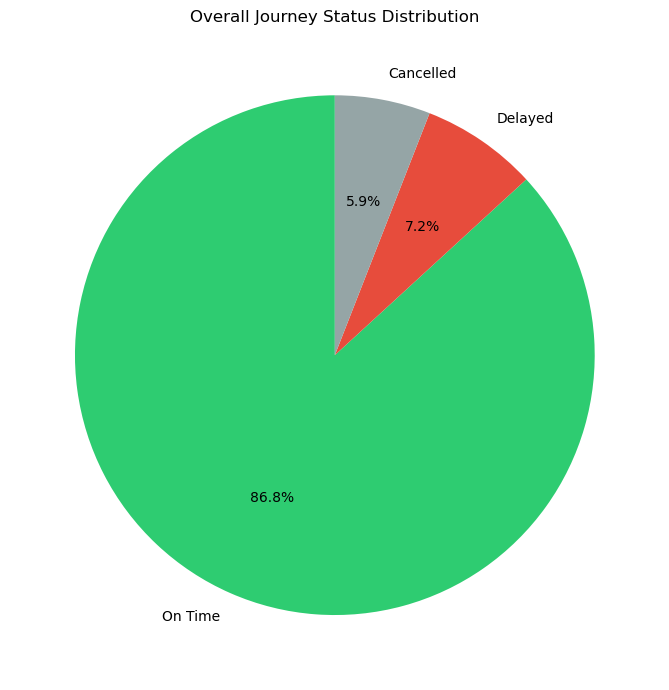

In [10]:
# Journey status breakdown
plt.figure(figsize=(7, 7))
labels = ['On Time', 'Delayed', 'Cancelled']
sizes = [27481, 2292, 1880]
colors = ['#2ecc71', '#e74c3c', '#95a5a6']

plt.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=90)
plt.title('Overall Journey Status Distribution')
plt.tight_layout()
plt.savefig('journey_status.png', dpi=150)
plt.show()